<a href="https://colab.research.google.com/github/thasithgajanayake/Telco-Customer-Churn/blob/main/Telco_Churn_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
# IMPORTS, DATA LOADING AND DATA CLEANING

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

# Set visual theme and create output folder for figures
sns.set_theme(style="whitegrid")
os.makedirs('figures', exist_ok=True)

# 1. Load dataset (ensure filename matches your uploaded CSV)
df = pd.read_csv('Telco-Customer-Churn.csv')

print("--- Dataset Shape ---")
print(df.shape)

print("\n--- Column Info ---")
df.info()

# 2. Clean TotalCharges (convert blank strings to NaN and impute with 0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"\nMissing values in TotalCharges before imputation: {df['TotalCharges'].isnull().sum()}")
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. Check target class distribution
print("\n--- Churn Class Distribution (%) ---")
print(df['Churn'].value_counts(normalize=True) * 100)

--- Dataset Shape ---
(7043, 21)

--- Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   o

In [24]:
# TASK 1 - EXPLORATORY DATA ANALYSIS & VISUALIZATION

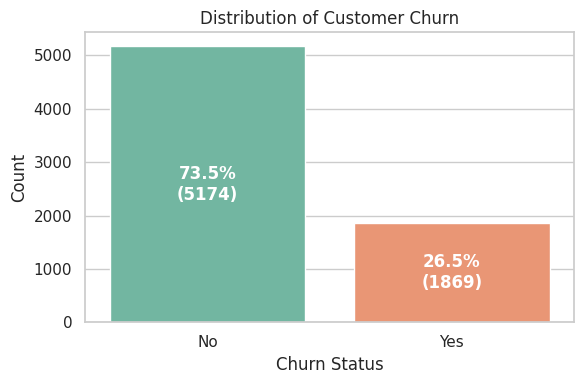

In [25]:
# Figure 1: Target Variable Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Distribution of Customer Churn', fontsize=12)
plt.xlabel('Churn Status')
plt.ylabel('Count')

total = len(df)
for p in ax.patches:
    pct = f'{100 * p.get_height() / total:.1f}%\n({int(p.get_height())})'
    ax.annotate(pct, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', weight='bold')

plt.tight_layout()
plt.savefig('figures/01_churn_distribution.png', dpi=300)
plt.show()

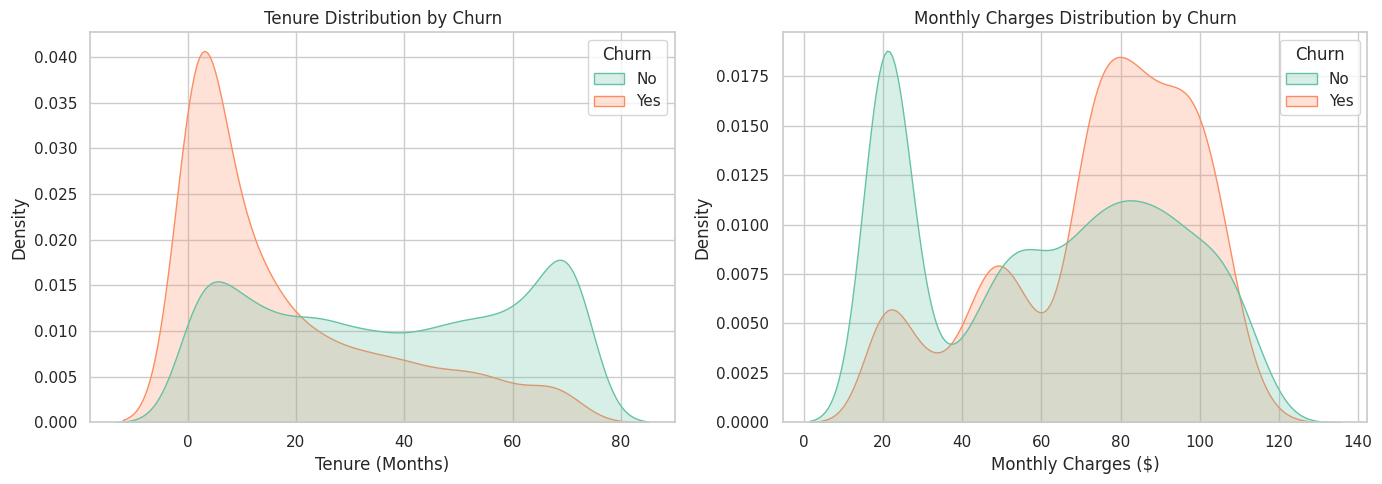

In [26]:
# Figure 2: Numerical Feature Distributions by Churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, fill=True, palette='Set2', ax=axes[0])
axes[0].set_title('Tenure Distribution by Churn')
axes[0].set_xlabel('Tenure (Months)')

sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, fill=True, palette='Set2', ax=axes[1])
axes[1].set_title('Monthly Charges Distribution by Churn')
axes[1].set_xlabel('Monthly Charges ($)')

plt.tight_layout()
plt.savefig('figures/02_numerical_distributions.png', dpi=300)
plt.show()

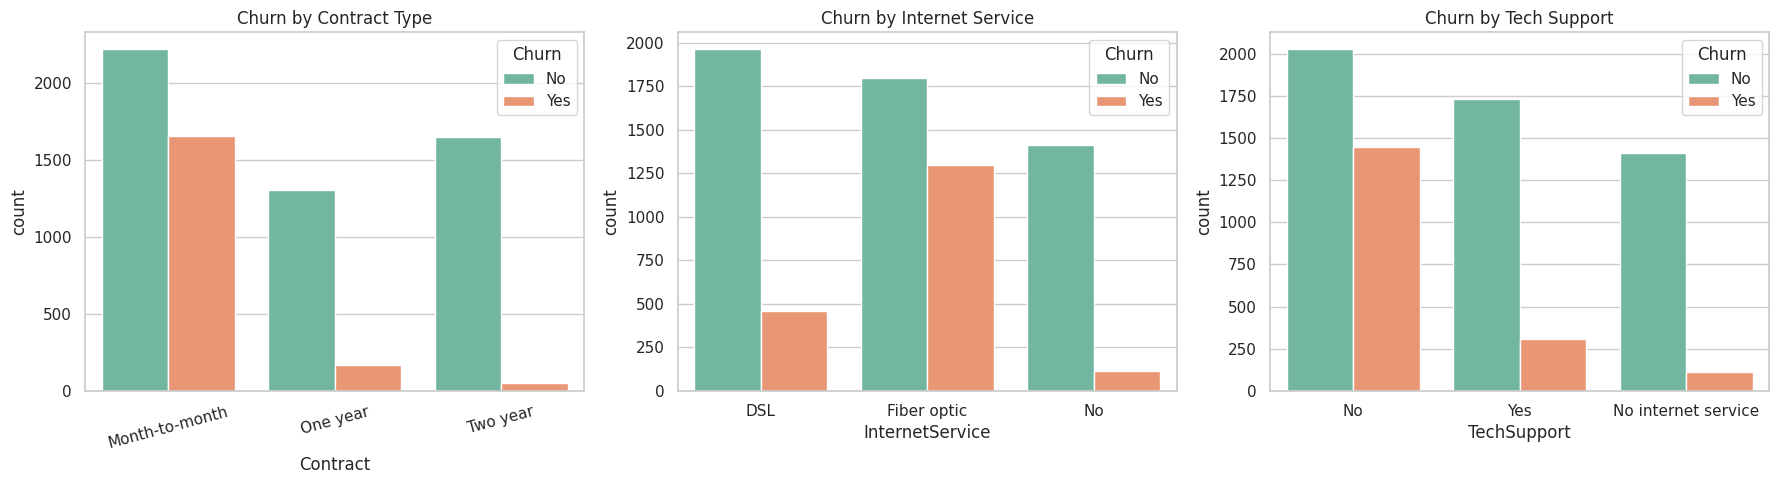

In [27]:
# Figure 3: Categorical Churn Drivers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2', ax=axes[0])
axes[0].set_title('Churn by Contract Type')
axes[0].tick_params(axis='x', rotation=15)

sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2', ax=axes[1])
axes[1].set_title('Churn by Internet Service')

sns.countplot(data=df, x='TechSupport', hue='Churn', palette='Set2', ax=axes[2])
axes[2].set_title('Churn by Tech Support')

plt.tight_layout()
plt.savefig('figures/03_categorical_drivers.png', dpi=300)
plt.show()

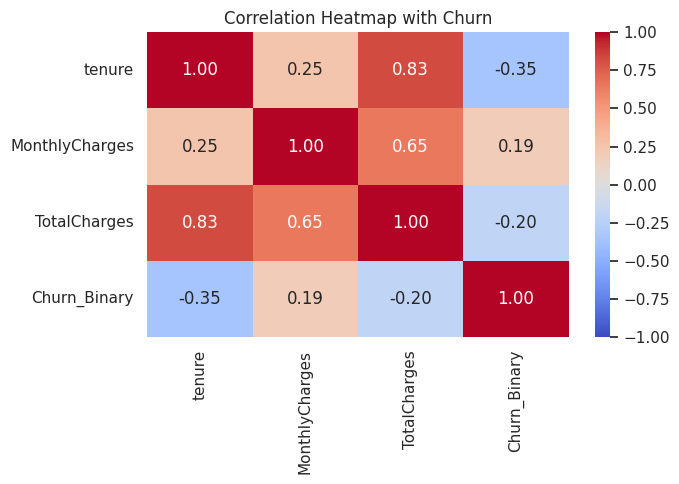

In [28]:
# Figure 4: Correlation Heatmap
plt.figure(figsize=(7, 5))
numeric_df = df[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()
numeric_df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Heatmap with Churn')
plt.tight_layout()
plt.savefig('figures/04_correlation_heatmap.png', dpi=300)
plt.show()

In [ ]:
# TASK 2 - PREPROCESSING, BASELINE MODELS AND HYPERPARAMETER TUNING

In [29]:
# 1. Prepare features and target
df_ml = df.drop(columns=['customerID']).copy()
df_ml['Churn'] = df_ml['Churn'].map({'Yes': 1, 'No': 0})

X = df_ml.drop(columns=['Churn'])
y = df_ml['Churn']

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

# Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
    ]
)

# 2. Experimental Setting 1: Baseline (Default) Models
baseline_models = {
    'Logistic Regression (Baseline)': LogisticRegression(max_iter=1000, random_state=42),
    'KNN (Baseline)': KNeighborsClassifier(),
    'Random Forest (Baseline)': RandomForestClassifier(random_state=42)
}

results = []

print("=== EVALUATING BASELINE MODELS ===")
for name, model in baseline_models.items():
    pipe = Pipeline(steps=[('prep', preprocessor), ('clf', model)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Setting': 'Baseline',
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

# 3. Experimental Setting 2: Hyperparameter Tuning (GridSearchCV)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_lr = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
pipe_knn = Pipeline([('prep', preprocessor), ('clf', KNeighborsClassifier())])
pipe_rf = Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=42))])

param_grid_lr = {
    'clf__C': [0.01, 0.1, 1.0, 10.0],
    'clf__class_weight': [None, 'balanced'],
    'clf__solver': ['lbfgs']
}

param_grid_knn = {
    'clf__n_neighbors': [5, 9, 15, 21, 27],
    'clf__weights': ['uniform', 'distance'],
    'clf__metric': ['euclidean', 'manhattan']
}

param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [5, 10, None],
    'clf__min_samples_split': [2, 5],
    'clf__class_weight': [None, 'balanced']
}

grid_searches = {
    'Logistic Regression (Tuned)': (pipe_lr, param_grid_lr),
    'KNN (Tuned)': (pipe_knn, param_grid_knn),
    'Random Forest (Tuned)': (pipe_rf, param_grid_rf)
}

best_estimators = {}

print("\n=== RUNNING HYPERPARAMETER TUNING ===")
for name, (pipe, p_grid) in grid_searches.items():
    print(f"Tuning {name}...")
    grid = GridSearchCV(pipe, p_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)

    best_pipe = grid.best_estimator_
    best_estimators[name] = best_pipe

    y_pred = best_pipe.predict(X_test)
    y_proba = best_pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Setting': 'Tuned',
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })
    print(f"Best Params for {name}: {grid.best_params_}")

# Display final comparison table
results_df = pd.DataFrame(results)
print("\n=== EXPERIMENTAL RESULTS COMPARISON ===")
display(results_df.round(4))


=== EVALUATING BASELINE MODELS ===

=== RUNNING HYPERPARAMETER TUNING ===
Tuning Logistic Regression (Tuned)...
Best Params for Logistic Regression (Tuned): {'clf__C': 10.0, 'clf__class_weight': None, 'clf__solver': 'lbfgs'}
Tuning KNN (Tuned)...
Best Params for KNN (Tuned): {'clf__metric': 'manhattan', 'clf__n_neighbors': 27, 'clf__weights': 'uniform'}
Tuning Random Forest (Tuned)...
Best Params for Random Forest (Tuned): {'clf__class_weight': 'balanced', 'clf__max_depth': 5, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}

=== EXPERIMENTAL RESULTS COMPARISON ===


,Model,Setting,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Baseline),Baseline,0.8062,0.6593,0.5588,0.6049,0.8422
1,KNN (Baseline),Baseline,0.7630,0.5538,0.5508,0.5523,0.7929
2,Random Forest (Baseline),Baseline,0.7921,0.6421,0.4893,0.5554,0.8275
3,Logistic Regression (Tuned),Tuned,0.8055,0.6572,0.5588,0.6040,0.8413
4,KNN (Tuned),Tuned,0.7878,0.6093,0.5588,0.5830,0.8308
5,Random Forest (Tuned),Tuned,0.7367,0.5025,0.8075,0.6195,0.8415


In [ ]:
# TASK 2 - EVALUATION VISUALIZATIONS

In [ ]:
# Figure 5: Combined ROC Curve for Tuned Models
plt.figure(figsize=(8, 6))
for name, model in best_estimators.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Tuned Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/05_roc_curves_tuned.png', dpi=300)
plt.show()


In [ ]:
# Figure 6: Confusion Matrices for Tuned Models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, best_estimators.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
    ax.set_title(f'CM: {name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('figures/06_confusion_matrices.png', dpi=300)
plt.show()
